# RQ2: restricted updates — final results

E3 anchoring and E4 freezing reuse one factorial. E5 DiagScale and E6 LoRA are specified recipes with different sampling, episode sizes, precision and regularization; they do not isolate adapter mechanisms. Final evaluation averages five paired outer folds within table, then weights tables equally. AUC/R² gains are CPT minus original; Brier/RMSE gains reverse direction. RMSE gains here are relative percentages.

## 0. Evidence and interpretation

The selected local evidence is a snapshot. Missing evidence remains unavailable; queued VSC jobs are not completed results.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from src.visualize import style, campaign as cp, questions as rq, synthesis as sy, research_views as rv
from src.visualize import choice_effects as ce, comparisons as cmp, publication as pub, dashboards as db
from src.visualize import diagnostics as dg
from src.visualize import training_summary as ts, pilots as pv, finishing as finish, prediction_diagnostics as pred
from src.visualize.figures import FigureSaver
from src.visualize.inputs import source_description
style.apply()
sink = FigureSaver('rq2/02_results')
report = cp.NotebookReport('RQ2: restricted updates — final results', sink=sink)
print(source_description())
report.add('0. Evidence and interpretation', source_description() + '\n' + 'E3 anchoring and E4 freezing reuse one factorial. E5 DiagScale and E6 LoRA are specified recipes with different sampling, episode sizes, precision and regularization; they do not isolate adapter mechanisms. Final evaluation averages five paired outer folds within table, then weights tables equally. AUC/R² gains are CPT minus original; Brier/RMSE gains reverse direction. RMSE gains here are relative percentages.')

DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.


## 1. Coverage, protocols and unique evidence

Training completion and benchmark completion are separate. All results retain their own matched original checkpoint. The current inference-policy table governs cross-study TabICL comparisons; a pending FP32 refresh is not published evidence.

In [2]:
QUESTION = 2
studies = {track: rq.load(QUESTION, track) for track in ('pd', 'lgd')}
catalogs = {}
for track, values in studies.items():
    report.table(track.upper() + ' unique trial inventory', rv.inventory_summary(rv.unique_training_inventory(values)))
    report.table(track.upper() + ' recipe and inference comparability', sy.comparability_table(values))
    for e, arm, run in values:
        report.table(track.upper() + ' ' + str(run.cfg.run_name) + ' ' + str(arm or '') + ' five-fold coverage', cmp.benchmark_coverage(run))
    catalogs[track] = {(domain, metric): rq.catalog(values, QUESTION, metric, domain, reference_only=QUESTION == 2)
                       for domain in ('credit', 'ood') for metric in (sy.PRIMARY[track], sy.SECONDARY[track])}
report.add('1. Coverage, protocols and unique evidence', 'Training completion and benchmark completion are separate. All results retain their own matched original checkpoint. The current inference-policy table governs cross-study TabICL comparisons; a pending FP32 refresh is not published evidence.')

C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


...

,public_studies,campaign,base,status,unique_trials
0,"1,3,4",cpt_main_v5,TabICLv2,OK,64
1,"1,3,4",cpt_main_v5,TabPFN v2,OK,64
2,"1,3,4",cpt_main_v5,TabPFN v2.6,OK,64
3,"1,3,4",cpt_main_v5,TabPFN v3,OK,64
4,5,cpt_diagscale_v1,TabICLv2,OK,12
5,5,cpt_diagscale_v1,TabPFN v3,OK,12
6,6,cpt_lora_v1,TabICLv2,OK,12
7,6,cpt_lora_v1,TabPFN v3,OK,12


,experiments,study,campaign,arm,bases,learning_rates,l2sp,pd_sampling,training_amp,tabicl_inference,episode_rows,seed,trials
0,"1, 3, 4 (shared)",Main grid,cpt_main_v5,,"TabICLv2, TabPFN v2, TabPFN v2.6, TabPFN v3","3e-07, 1e-06, 1e-05, 3e-05","0, 0.003",uniform rows,True,"FP32, no FA3",measured cap,42,256
1,5,DiagScale,cpt_diagscale_v1,,"TabICLv2, TabPFN v3","0.0001, 0.001, 0.03",0,uniform rows,False,"FP32, no FA3",8192,42,24
2,6,LoRA,cpt_lora_v1,,"TabICLv2, TabPFN v3","1e-05, 0.0001, 0.001",0,uniform rows,True,"FP32, no FA3",measured cap,42,24


,domain,base,planned_checkpoints,completed_checkpoints,paired_five_fold_comparisons,paired_datasets
0,credit,TabICLv2,64,64,128,8
1,credit,TabPFN v2,64,64,128,8
2,credit,TabPFN v2.6,64,64,128,8
3,credit,TabPFN v3,64,64,128,8
4,ood,TabICLv2,64,64,256,4
5,ood,TabPFN v2,64,64,256,4
6,ood,TabPFN v2.6,64,64,256,4
7,ood,TabPFN v3,64,64,256,4


,domain,base,planned_checkpoints,completed_checkpoints,paired_five_fold_comparisons,paired_datasets
0,credit,TabICLv2,12,12,24,8
1,credit,TabPFN v3,12,12,24,8
2,ood,TabICLv2,12,12,48,4
3,ood,TabPFN v3,12,12,48,4


,domain,base,planned_checkpoints,completed_checkpoints,paired_five_fold_comparisons,paired_datasets
0,credit,TabICLv2,12,12,24,8
1,credit,TabPFN v3,12,12,24,8
2,ood,TabICLv2,12,12,48,4
3,ood,TabPFN v3,12,12,48,4


## 2. The complete anchoring × freezing factorial

Show all four cells jointly, rather than repeating two separate experiment narratives. Their anchoring/freezing simple effects and interaction remain in the numerical record. Positive changes relative to the original are different from merely reducing degradation.

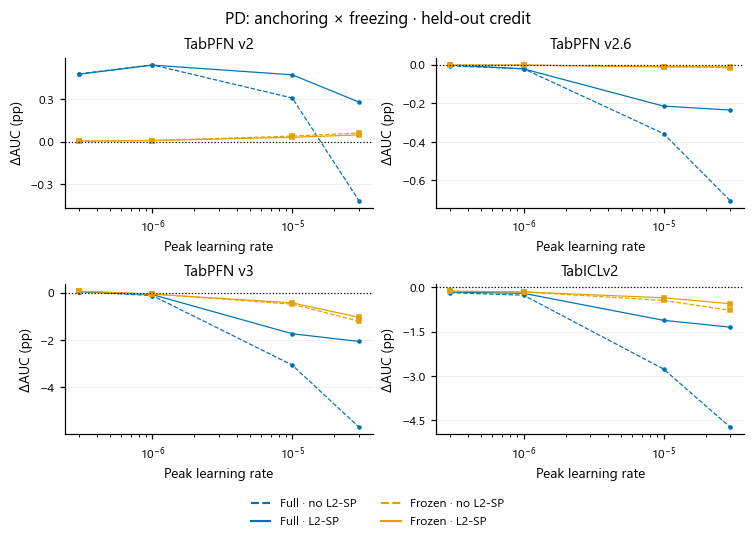

PD. Complete full/frozen × unanchored/anchored factorial on held-out credit tables. All four cells and all learning rates use a fixed complete table cohort within each model. Positive values favor CPT relative to its original checkpoint. Five folds are averaged within table; retention first averages the four training partitions, then tables receive equal weight. The full and frozen anchoring effects, both freezing effects and their difference-in-differences interaction are retained in the summary. E1/E3/E4 reuse one 512-run campaign, not independent repetitions.

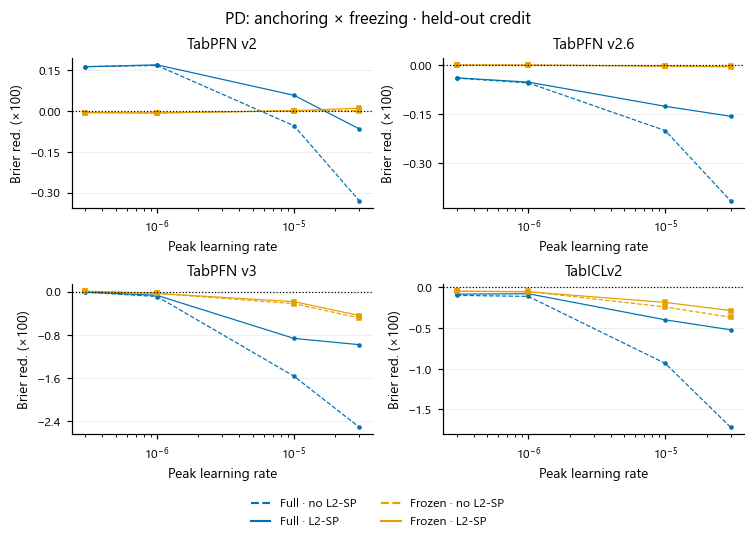

PD. Complete full/frozen × unanchored/anchored factorial on held-out credit tables. All four cells and all learning rates use a fixed complete table cohort within each model. Positive values favor CPT relative to its original checkpoint. Five folds are averaged within table; retention first averages the four training partitions, then tables receive equal weight. The full and frozen anchoring effects, both freezing effects and their difference-in-differences interaction are retained in the summary. E1/E3/E4 reuse one 512-run campaign, not independent repetitions.

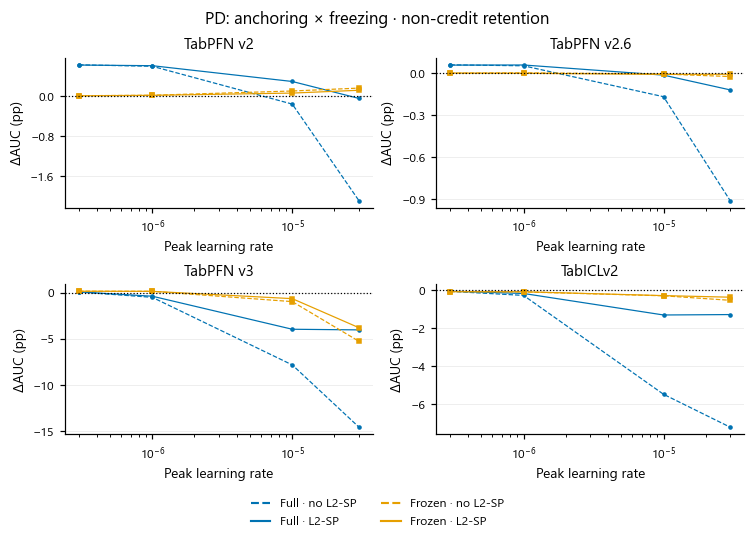

PD. Complete full/frozen × unanchored/anchored factorial on non-credit retention tables. All four cells and all learning rates use a fixed complete table cohort within each model. Positive values favor CPT relative to its original checkpoint. Five folds are averaged within table; retention first averages the four training partitions, then tables receive equal weight. The full and frozen anchoring effects, both freezing effects and their difference-in-differences interaction are retained in the summary. E1/E3/E4 reuse one 512-run campaign, not independent repetitions.

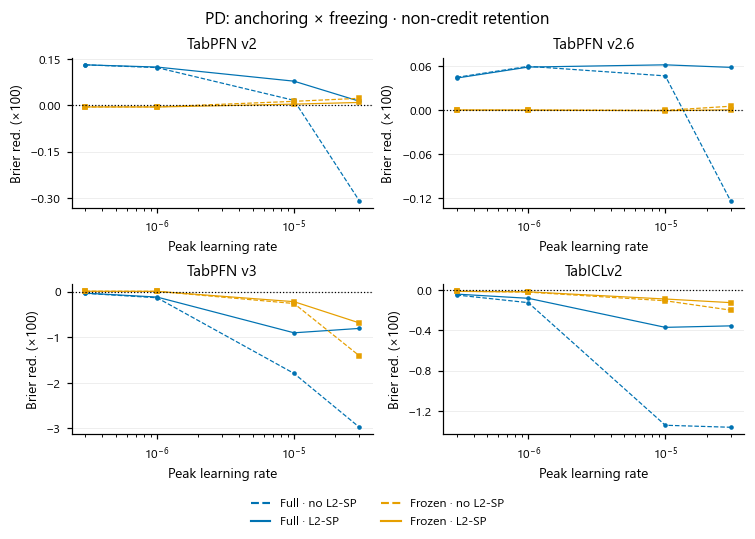

PD. Complete full/frozen × unanchored/anchored factorial on non-credit retention tables. All four cells and all learning rates use a fixed complete table cohort within each model. Positive values favor CPT relative to its original checkpoint. Five folds are averaged within table; retention first averages the four training partitions, then tables receive equal weight. The full and frozen anchoring effects, both freezing effects and their difference-in-differences interaction are retained in the summary. E1/E3/E4 reuse one 512-run campaign, not independent repetitions.

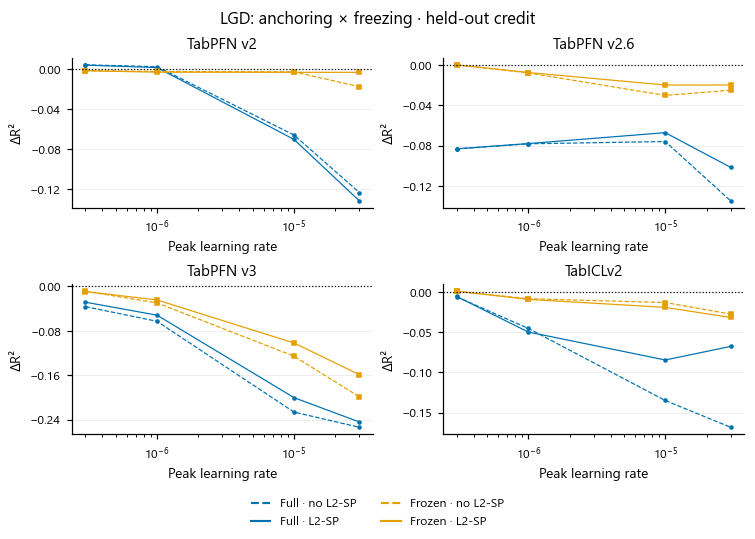

LGD. Complete full/frozen × unanchored/anchored factorial on held-out credit tables. All four cells and all learning rates use a fixed complete table cohort within each model. Positive values favor CPT relative to its original checkpoint. Five folds are averaged within table; retention first averages the four training partitions, then tables receive equal weight. The full and frozen anchoring effects, both freezing effects and their difference-in-differences interaction are retained in the summary. E1/E3/E4 reuse one 512-run campaign, not independent repetitions.

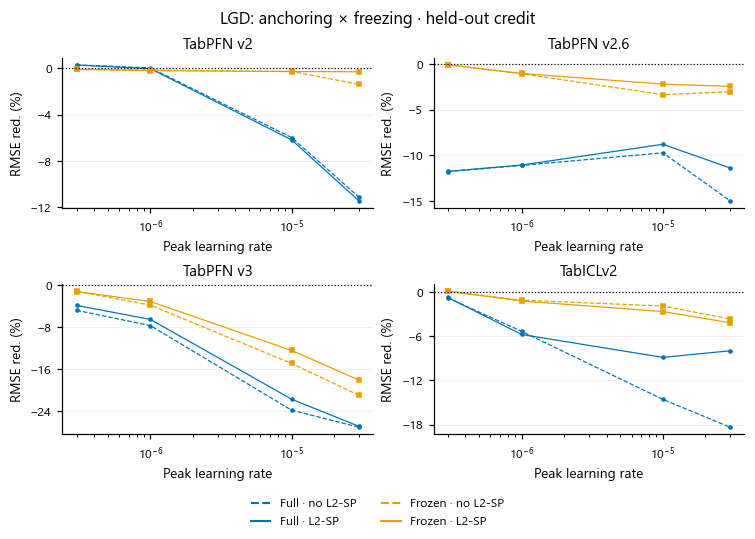

LGD. Complete full/frozen × unanchored/anchored factorial on held-out credit tables. All four cells and all learning rates use a fixed complete table cohort within each model. Positive values favor CPT relative to its original checkpoint. Five folds are averaged within table; retention first averages the four training partitions, then tables receive equal weight. The full and frozen anchoring effects, both freezing effects and their difference-in-differences interaction are retained in the summary. E1/E3/E4 reuse one 512-run campaign, not independent repetitions.

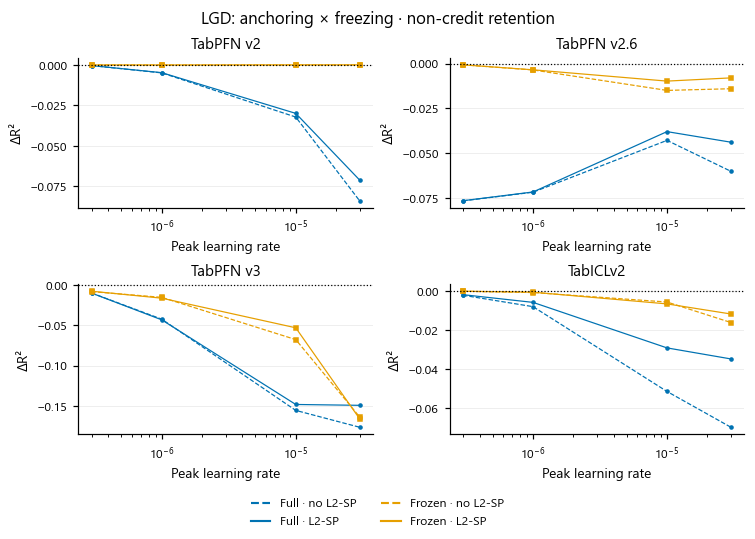

LGD. Complete full/frozen × unanchored/anchored factorial on non-credit retention tables. All four cells and all learning rates use a fixed complete table cohort within each model. Positive values favor CPT relative to its original checkpoint. Five folds are averaged within table; retention first averages the four training partitions, then tables receive equal weight. The full and frozen anchoring effects, both freezing effects and their difference-in-differences interaction are retained in the summary. E1/E3/E4 reuse one 512-run campaign, not independent repetitions.

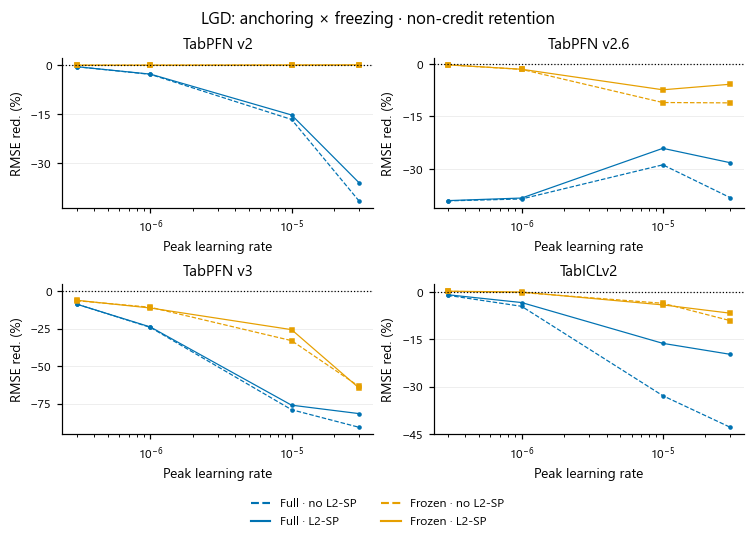

LGD. Complete full/frozen × unanchored/anchored factorial on non-credit retention tables. All four cells and all learning rates use a fixed complete table cohort within each model. Positive values favor CPT relative to its original checkpoint. Five folds are averaged within table; retention first averages the four training partitions, then tables receive equal weight. The full and frozen anchoring effects, both freezing effects and their difference-in-differences interaction are retained in the summary. E1/E3/E4 reuse one 512-run campaign, not independent repetitions.

In [3]:
for track, values in studies.items():
    main = next(run for e, arm, run in values if e == 1)
    grid = ce.benchmark_grid(main)
    for domain in ('credit', 'ood'):
        cp.show(sink, rq.plot_factorial(grid, track, domain), track=track)
report.add('2. The complete anchoring × freezing factorial', 'Show all four cells jointly, rather than repeating two separate experiment narratives. Their anchoring/freezing simple effects and interaction remain in the numerical record. Positive changes relative to the original are different from merely reducing degradation.')

## 3. Adapter recipes and the predefined full-update reference

DiagScale and LoRA appear together at all prescribed rates on a fixed table cohort, with the predefined full-update reference for context. They differ in more than the adapter; no mechanism ranking follows from this comparison.

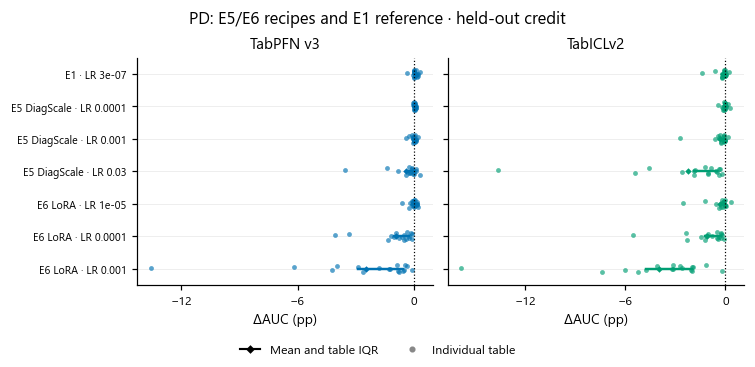

PD. E5/E6 recipes and E1 reference · held-out credit. Each CPT recipe is compared with its own original model; positive values favor CPT. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Each model uses the same table cohort across all displayed arms; models can have different cohorts. Dots are individual tables, diamonds equal-table means and segments table interquartile ranges, not confidence intervals. Axes retain all finite values and can differ between models. Missing recipes are reported in coverage, not assigned zero. Bases without an available adapter comparison are omitted from this panel. Original scores, adapted scores and named-table effects are retained in the text summary.

,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabICLv2,roc_auc,17,0.797067,0.795485,-0.001581,...,-1.756813e-03,0.000039,-0.014006,0.002416,1,10,6,27,85,0.058824
1,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabPFN v2,roc_auc,17,0.778915,0.783687,0.004773,...,2.890096e-03,0.006384,0.000037,0.009349,16,1,0,80,85,0.941176
2,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabPFN v2.6,roc_auc,17,0.792242,0.792218,-0.000024,...,-6.287806e-04,0.000164,-0.002185,0.004683,2,13,2,30,85,0.117647
3,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabPFN v3,roc_auc,17,0.798170,0.798600,0.000430,...,-4.109962e-05,0.001216,-0.003600,0.002996,5,11,1,52,85,0.294118
4,5,DiagScale,DiagScale,E5 LR 0.0001,TabICLv2,roc_auc,17,0.797067,0.796600,-0.000467,...,-1.013734e-03,-0.000072,-0.004630,0.002525,2,10,5,20,85,0.117647
5,5,DiagScale,DiagScale,E5 LR 0.0001,TabPFN v3,roc_auc,17,0.798177,0.798393,0.000216,...,3.497927e-07,0.000560,-0.000750,0.001030,1,16,0,54,85,0.058824
6,5,DiagScale,DiagScale,E5 LR 0.001,TabICLv2,roc_auc,17,0.797067,0.793845,-0.003222,...,-3.143543e-03,-0.000608,-0.027312,0.001409,1,7,9,16,85,0.058824
7,5,DiagScale,DiagScale,E5 LR 0.001,TabPFN v3,roc_auc,17,0.798177,0.797911,-0.000266,...,-6.710477e-04,0.000597,-0.004241,0.001979,3,12,2,35,85,0.176471
8,5,DiagScale,DiagScale,E5 LR 0.03,TabICLv2,roc_auc,17,0.797067,0.774497,-0.022570,...,-1.890527e-02,-0.005141,-0.136484,-0.001810,0,0,17,6,85,0.000000
9,5,DiagScale,DiagScale,E5 LR 0.03,TabPFN v3,roc_auc,17,0.798177,0.794052,-0.004124,...,-2.752586e-03,-0.000092,-0.035535,0.002788,2,6,9,20,85,0.117647


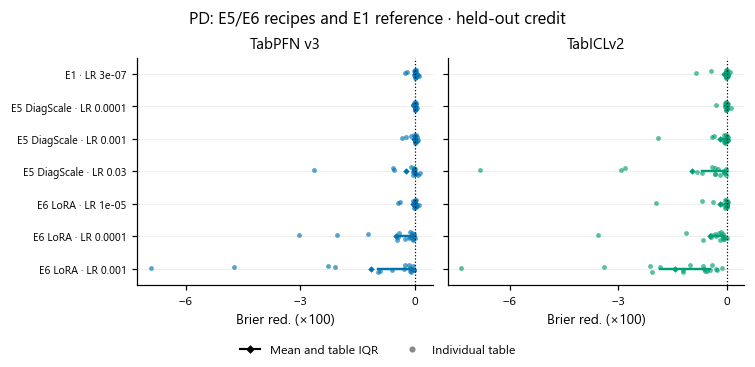

PD. E5/E6 recipes and E1 reference · held-out credit. Each CPT recipe is compared with its own original model; positive values favor CPT. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Each model uses the same table cohort across all displayed arms; models can have different cohorts. Dots are individual tables, diamonds equal-table means and segments table interquartile ranges, not confidence intervals. Axes retain all finite values and can differ between models. Missing recipes are reported in coverage, not assigned zero. Bases without an available adapter comparison are omitted from this panel. Original scores, adapted scores and named-table effects are retained in the text summary.

,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabICLv2,brier_score,17,0.112620,0.113465,-0.000845,...,-0.000341,0.000001,-0.008612,0.000640,2,6,9,29,85,0.117647
1,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabPFN v2,brier_score,17,0.118123,0.116491,0.001632,...,0.000495,0.001400,0.000234,0.009307,17,0,0,79,85,1.000000
2,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabPFN v2.6,brier_score,17,0.113695,0.114092,-0.000397,...,-0.000168,0.000005,-0.004069,0.000378,1,11,5,20,85,0.058824
3,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabPFN v3,brier_score,17,0.111856,0.111921,-0.000065,...,-0.000024,0.000300,-0.002498,0.001013,8,5,4,61,85,0.470588
4,5,DiagScale,DiagScale,E5 LR 0.0001,TabICLv2,brier_score,17,0.112620,0.112910,-0.000290,...,-0.000334,-0.000032,-0.002967,0.001000,2,7,8,18,85,0.117647
5,5,DiagScale,DiagScale,E5 LR 0.0001,TabPFN v3,brier_score,17,0.111856,0.111828,0.000028,...,0.000003,0.000144,-0.000523,0.000514,6,8,3,58,85,0.352941
6,5,DiagScale,DiagScale,E5 LR 0.001,TabICLv2,brier_score,17,0.112620,0.114505,-0.001886,...,-0.001007,-0.000083,-0.019052,0.000295,3,2,12,17,85,0.176471
7,5,DiagScale,DiagScale,E5 LR 0.001,TabPFN v3,brier_score,17,0.111856,0.112122,-0.000266,...,-0.000087,0.000180,-0.003370,0.000866,5,8,4,39,85,0.294118
8,5,DiagScale,DiagScale,E5 LR 0.03,TabICLv2,brier_score,17,0.112620,0.122238,-0.009618,...,-0.007022,-0.000824,-0.068082,-0.000380,0,0,17,7,85,0.000000
9,5,DiagScale,DiagScale,E5 LR 0.03,TabPFN v3,brier_score,17,0.111856,0.114101,-0.002245,...,-0.000554,-0.000042,-0.026348,0.001318,3,4,10,22,85,0.176471


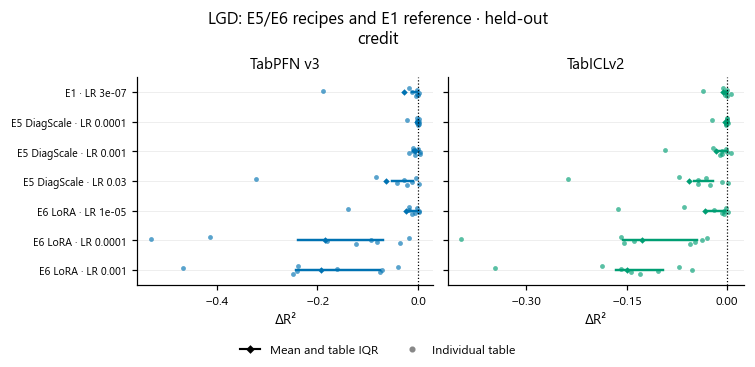

LGD. E5/E6 recipes and E1 reference · held-out credit. Each CPT recipe is compared with its own original model; positive values favor CPT. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Each model uses the same table cohort across all displayed arms; models can have different cohorts. Dots are individual tables, diamonds equal-table means and segments table interquartile ranges, not confidence intervals. Axes retain all finite values and can differ between models. Missing recipes are reported in coverage, not assigned zero. Bases without an available adapter comparison are omitted from this panel. Original scores, adapted scores and named-table effects are retained in the text summary.

,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabICLv2,r2,8,0.531911,0.526426,-0.005485,...,-0.004021,-2.224684e-04,-0.035748,0.005838,1,2,5,13,40,0.125
1,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabPFN v2,r2,8,0.474518,0.478619,0.004101,...,-0.001140,7.654214e-03,-0.003251,0.018483,4,2,2,20,40,0.500
2,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabPFN v2.6,r2,8,0.539808,0.456595,-0.083212,...,-0.076910,-4.786778e-02,-0.298833,0.001434,1,0,7,5,40,0.125
3,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabPFN v3,r2,8,0.539412,0.510983,-0.028429,...,-0.013203,-1.797053e-03,-0.189834,0.002197,1,0,7,10,40,0.125
4,5,DiagScale,DiagScale,E5 LR 0.0001,TabICLv2,r2,8,0.531911,0.528825,-0.003086,...,-0.001067,-8.374453e-07,-0.022995,0.001281,1,5,2,17,40,0.125
5,5,DiagScale,DiagScale,E5 LR 0.0001,TabPFN v3,r2,8,0.539412,0.536081,-0.003330,...,-0.003151,6.642044e-04,-0.021596,0.002355,1,3,4,16,40,0.125
6,5,DiagScale,DiagScale,E5 LR 0.001,TabICLv2,r2,8,0.531911,0.515107,-0.016804,...,-0.012857,-5.481213e-04,-0.093165,0.005906,1,2,5,9,40,0.125
7,5,DiagScale,DiagScale,E5 LR 0.001,TabPFN v3,r2,8,0.539412,0.533466,-0.005945,...,-0.009623,6.537676e-04,-0.018097,0.003557,2,1,5,13,40,0.250
8,5,DiagScale,DiagScale,E5 LR 0.03,TabICLv2,r2,8,0.531911,0.474919,-0.056992,...,-0.049896,-2.057860e-02,-0.237289,0.001238,1,0,7,4,40,0.125
9,5,DiagScale,DiagScale,E5 LR 0.03,TabPFN v3,r2,8,0.539412,0.475081,-0.064331,...,-0.052367,-9.813258e-03,-0.322349,0.001097,1,0,7,3,40,0.125


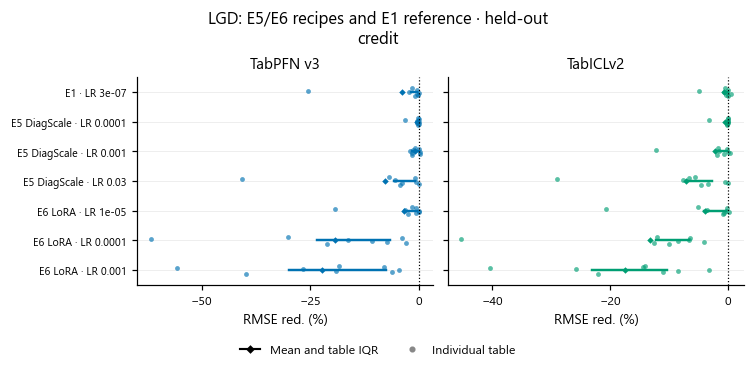

LGD. E5/E6 recipes and E1 reference · held-out credit. Each CPT recipe is compared with its own original model; positive values favor CPT. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Each model uses the same table cohort across all displayed arms; models can have different cohorts. Dots are individual tables, diamonds equal-table means and segments table interquartile ranges, not confidence intervals. Axes retain all finite values and can differ between models. Missing recipes are reported in coverage, not assigned zero. Bases without an available adapter comparison are omitted from this panel. Original scores, adapted scores and named-table effects are retained in the text summary.

,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabICLv2,rmse,8,0.224874,0.226611,-0.007277,...,-0.004959,-2.640522e-04,-0.048784,0.005110,1,3,4,13,40,0.125
1,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabPFN v2,rmse,8,0.240824,0.239822,0.002710,...,-0.001660,5.725004e-03,-0.004391,0.012321,4,1,3,20,40,0.500
2,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabPFN v2.6,rmse,8,0.221788,0.244728,-0.117757,...,-0.121625,-5.160246e-02,-0.435766,0.000786,0,1,7,5,40,0.000
3,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabPFN v3,rmse,8,0.222704,0.231491,-0.038738,...,-0.016796,-2.827270e-03,-0.256139,0.001321,1,1,6,10,40,0.125
4,5,DiagScale,DiagScale,E5 LR 0.0001,TabICLv2,rmse,8,0.224874,0.225919,-0.004336,...,-0.001677,6.788881e-07,-0.031660,0.001040,1,4,3,17,40,0.125
5,5,DiagScale,DiagScale,E5 LR 0.0001,TabPFN v3,rmse,8,0.222704,0.223836,-0.005035,...,-0.003598,6.609969e-04,-0.032380,0.001608,2,2,4,16,40,0.250
6,5,DiagScale,DiagScale,E5 LR 0.001,TabICLv2,rmse,8,0.224874,0.229897,-0.022156,...,-0.017057,-1.165587e-03,-0.122763,0.003962,1,1,6,9,40,0.125
7,5,DiagScale,DiagScale,E5 LR 0.001,TabPFN v3,rmse,8,0.222704,0.224309,-0.008517,...,-0.015486,1.618687e-04,-0.019420,0.002931,2,1,5,13,40,0.250
8,5,DiagScale,DiagScale,E5 LR 0.03,TabICLv2,rmse,8,0.224874,0.240266,-0.071499,...,-0.067990,-2.690331e-02,-0.289812,0.000514,0,1,7,4,40,0.000
9,5,DiagScale,DiagScale,E5 LR 0.03,TabPFN v3,rmse,8,0.222704,0.240303,-0.078552,...,-0.057170,-8.727386e-03,-0.407977,-0.000307,0,1,7,3,40,0.000


In [4]:
for track in studies:
    for metric in (sy.PRIMARY[track], sy.SECONDARY[track]):
        data = catalogs[track]['credit', metric]
        cp.show(sink, rq.plot_effects(data, track, title='E5/E6 recipes and E1 reference · held-out credit', name='adapter_credit_' + metric, min_arms=2), track=track)
        report.table(track.upper() + ' absolute scores and paired effects: ' + metric, sy.summarize(data))
report.add('3. Adapter recipes and the predefined full-update reference', 'DiagScale and LoRA appear together at all prescribed rates on a fixed table cohort, with the predefined full-update reference for context. They differ in more than the adapter; no mechanism ranking follows from this comparison.')

## 4. Non-credit retention alongside transfer

The four same-task non-credit tables are a bounded retention panel. Their four training-partition results are averaged within table before equal-table summaries. Original/CPT comparisons remain paired within each recipe and precision policy.

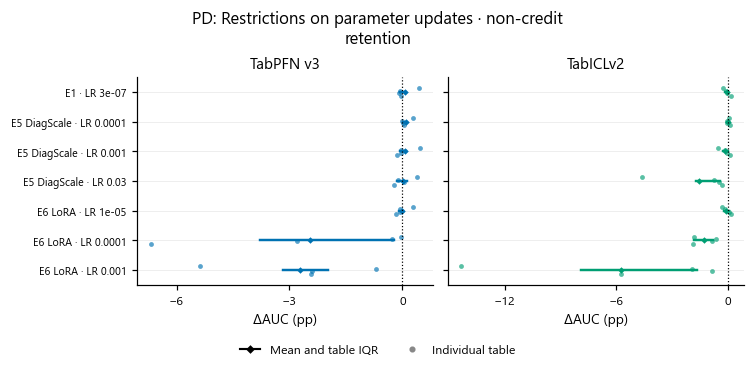

PD. Restrictions on parameter updates · non-credit retention. Each CPT recipe is compared with its own original model; positive values favor CPT. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Each model uses the same table cohort across all displayed arms; models can have different cohorts. Dots are individual tables, diamonds equal-table means and segments table interquartile ranges, not confidence intervals. Axes retain all finite values and can differ between models. Missing recipes are reported in coverage, not assigned zero. Bases without an available adapter comparison are omitted from this panel. Original scores, adapted scores and named-table effects are retained in the text summary.

,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabICLv2,roc_auc,4,0.874683,0.874268,-0.000414,...,-0.001347,0.000366,-0.002252,0.001728,1,1,2,31,80,0.25
1,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabPFN v2,roc_auc,4,0.848628,0.854870,0.006243,...,0.001877,0.006457,0.001442,0.019345,4,0,0,71,80,1.00
2,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabPFN v2.6,roc_auc,4,0.871975,0.872562,0.000586,...,-0.000132,0.001041,-0.000271,0.001972,1,3,0,50,80,0.25
3,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabPFN v3,roc_auc,4,0.872980,0.873677,0.000698,...,-0.000574,0.000834,-0.000794,0.004459,1,3,0,38,80,0.25
4,5,DiagScale,DiagScale,E5 LR 0.0001,TabICLv2,roc_auc,4,0.874683,0.874864,0.000181,...,-0.000345,0.000610,-0.000478,0.001037,1,3,0,31,80,0.25
5,5,DiagScale,DiagScale,E5 LR 0.0001,TabPFN v3,roc_auc,4,0.872980,0.873848,0.000868,...,0.000094,0.001075,-0.000065,0.002936,1,3,0,52,80,0.25
6,5,DiagScale,DiagScale,E5 LR 0.001,TabICLv2,roc_auc,4,0.874683,0.873287,-0.001396,...,-0.002407,0.000033,-0.005154,0.001529,1,1,2,27,80,0.25
7,5,DiagScale,DiagScale,E5 LR 0.001,TabPFN v3,roc_auc,4,0.872980,0.873687,0.000708,...,-0.000575,0.000998,-0.001291,0.004690,1,2,1,42,80,0.25
8,5,DiagScale,DiagScale,E5 LR 0.03,TabICLv2,roc_auc,4,0.874683,0.859498,-0.015185,...,-0.016805,-0.004258,-0.045998,-0.002988,0,0,4,12,80,0.00
9,5,DiagScale,DiagScale,E5 LR 0.03,TabPFN v3,roc_auc,4,0.872980,0.873195,0.000216,...,-0.001487,0.001261,-0.002245,0.003990,1,1,2,30,80,0.25


,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabICLv2,brier_score,4,0.062617,0.063039,-0.000421,...,-0.000825,-0.000061,-0.000973,0.000216,1,0,3,26,80,0.25
1,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabPFN v2,brier_score,4,0.066848,0.065531,0.001317,...,0.000596,0.001742,0.000385,0.002840,4,0,0,71,80,1.00
2,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabPFN v2.6,brier_score,4,0.064141,0.063703,0.000439,...,-0.000025,0.000547,-0.000075,0.001665,2,2,0,48,80,0.50
3,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabPFN v3,brier_score,4,0.062912,0.063243,-0.000331,...,-0.000512,0.000084,-0.001292,0.000163,1,1,2,36,80,0.25
4,5,DiagScale,DiagScale,E5 LR 0.0001,TabICLv2,brier_score,4,0.062617,0.062789,-0.000172,...,-0.000211,-0.000079,-0.000461,0.000010,0,1,3,26,80,0.00
5,5,DiagScale,DiagScale,E5 LR 0.0001,TabPFN v3,brier_score,4,0.062912,0.062924,-0.000012,...,-0.000036,0.000027,-0.000126,0.000070,0,3,1,43,80,0.00
6,5,DiagScale,DiagScale,E5 LR 0.001,TabICLv2,brier_score,4,0.062617,0.063439,-0.000822,...,-0.001270,-0.000384,-0.001623,0.000002,0,1,3,17,80,0.00
7,5,DiagScale,DiagScale,E5 LR 0.001,TabPFN v3,brier_score,4,0.062912,0.063162,-0.000250,...,-0.000353,0.000006,-0.000927,0.000124,1,1,2,36,80,0.25
8,5,DiagScale,DiagScale,E5 LR 0.03,TabICLv2,brier_score,4,0.062617,0.065903,-0.003285,...,-0.004585,-0.001742,-0.006788,-0.000269,0,0,4,9,80,0.00
9,5,DiagScale,DiagScale,E5 LR 0.03,TabPFN v3,brier_score,4,0.062912,0.063405,-0.000493,...,-0.000607,-0.000427,-0.000777,-0.000114,0,0,4,24,80,0.00


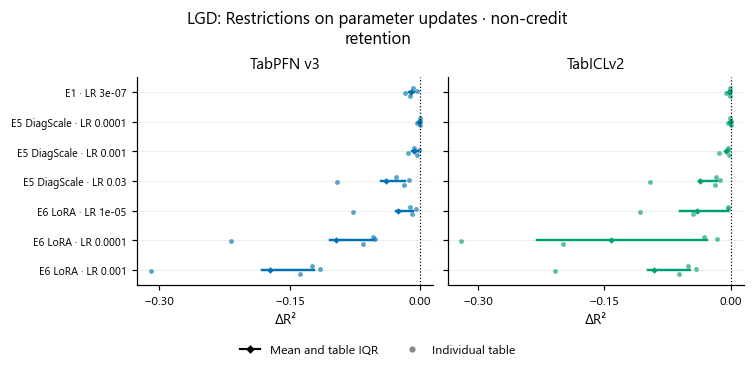

LGD. Restrictions on parameter updates · non-credit retention. Each CPT recipe is compared with its own original model; positive values favor CPT. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Each model uses the same table cohort across all displayed arms; models can have different cohorts. Dots are individual tables, diamonds equal-table means and segments table interquartile ranges, not confidence intervals. Axes retain all finite values and can differ between models. Missing recipes are reported in coverage, not assigned zero. Bases without an available adapter comparison are omitted from this panel. Original scores, adapted scores and named-table effects are retained in the text summary.

,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabICLv2,r2,4,0.904621,0.902774,-0.001847,...,-0.002112,-0.000525,-0.005352,-0.000461,0,2,2,14,80,0.00
1,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabPFN v2,r2,4,0.876377,0.876021,-0.000355,...,-0.001968,0.000873,-0.002444,0.002502,1,1,2,34,80,0.25
2,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabPFN v2.6,r2,4,0.900482,0.823971,-0.076512,...,-0.083587,-0.041825,-0.167859,-0.040389,0,0,4,0,80,0.00
3,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabPFN v3,r2,4,0.908113,0.897853,-0.010260,...,-0.013340,-0.007349,-0.017034,-0.003148,0,0,4,0,80,0.00
4,5,DiagScale,DiagScale,E5 LR 0.0001,TabICLv2,r2,4,0.904621,0.903958,-0.000663,...,-0.000819,0.000046,-0.002759,0.000328,0,3,1,31,80,0.00
5,5,DiagScale,DiagScale,E5 LR 0.0001,TabPFN v3,r2,4,0.908115,0.906884,-0.001231,...,-0.001384,-0.000482,-0.003378,-0.000273,0,3,1,15,80,0.00
6,5,DiagScale,DiagScale,E5 LR 0.001,TabICLv2,r2,4,0.904621,0.899129,-0.005492,...,-0.005746,-0.002576,-0.014267,-0.002044,0,0,4,4,80,0.00
7,5,DiagScale,DiagScale,E5 LR 0.001,TabPFN v3,r2,4,0.908115,0.901480,-0.006634,...,-0.008984,-0.003083,-0.014498,-0.001176,0,0,4,5,80,0.00
8,5,DiagScale,DiagScale,E5 LR 0.03,TabICLv2,r2,4,0.904621,0.868723,-0.035898,...,-0.037514,-0.016179,-0.095066,-0.012935,0,0,4,0,80,0.00
9,5,DiagScale,DiagScale,E5 LR 0.03,TabPFN v3,r2,4,0.908115,0.869254,-0.038861,...,-0.045053,-0.017176,-0.096095,-0.012614,0,0,4,0,80,0.00


,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabICLv2,rmse,4,4.209030,4.241589,-0.008705,...,-0.010835,-0.006930,-0.011330,-0.005368,0,0,4,14,80,0.00
1,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabPFN v2,rmse,4,4.617752,4.605111,-0.004475,...,-0.011965,0.007091,-0.039503,0.022399,2,0,2,34,80,0.50
2,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabPFN v2.6,rmse,4,4.307522,5.779702,-0.390230,...,-0.410457,-0.319674,-0.582931,-0.298189,0,0,4,0,80,0.00
3,1,Main grid,Full CPT,Grid all · LR 3e-07 · λ 0.003,TabPFN v3,rmse,4,4.182164,4.469382,-0.086134,...,-0.109514,-0.035991,-0.193366,-0.032430,0,0,4,0,80,0.00
4,5,DiagScale,DiagScale,E5 LR 0.0001,TabICLv2,rmse,4,4.209030,4.211617,-0.001276,...,-0.003586,0.000726,-0.005857,0.003919,1,1,2,31,80,0.25
5,5,DiagScale,DiagScale,E5 LR 0.0001,TabPFN v3,rmse,4,4.182029,4.202225,-0.007068,...,-0.009302,-0.003563,-0.014634,-0.002044,0,0,4,15,80,0.00
6,5,DiagScale,DiagScale,E5 LR 0.001,TabICLv2,rmse,4,4.209030,4.303157,-0.030797,...,-0.035585,-0.023143,-0.052649,-0.014676,0,0,4,4,80,0.00
7,5,DiagScale,DiagScale,E5 LR 0.001,TabPFN v3,rmse,4,4.182029,4.313048,-0.056196,...,-0.062704,-0.022648,-0.155334,-0.011141,0,0,4,5,80,0.00
8,5,DiagScale,DiagScale,E5 LR 0.03,TabICLv2,rmse,4,4.209030,4.813898,-0.178997,...,-0.208630,-0.123812,-0.285464,-0.123637,0,0,4,0,80,0.00
9,5,DiagScale,DiagScale,E5 LR 0.03,TabPFN v3,rmse,4,4.182029,4.843188,-0.241374,...,-0.276604,-0.123630,-0.530959,-0.116818,0,0,4,0,80,0.00


In [5]:
for track, values in studies.items():
    primary = catalogs[track]['credit', sy.PRIMARY[track]]
    retention = catalogs[track]['ood', sy.PRIMARY[track]]
    cp.show(sink, rq.plot_effects(retention, track, title=rq.TITLES[QUESTION] + ' · non-credit retention', name='retention_' + sy.PRIMARY[track], min_arms=2 if QUESTION == 2 else 1), track=track)
    for metric in (sy.PRIMARY[track], sy.SECONDARY[track]):
        report.table(track.upper() + ' non-credit absolute scores and effects: ' + metric, sy.summarize(catalogs[track]['ood', metric]))
report.add('4. Non-credit retention alongside transfer', 'The four same-task non-credit tables are a bounded retention panel. Their four training-partition results are averaged within table before equal-table summaries. Original/CPT comparisons remain paired within each recipe and precision policy.')

## 5. Secondary outcomes and saved-prediction evidence

Calibration, log loss and regression errors retain their distinct meanings. Detailed per-table prediction summaries remain available without another repeated figure for each experiment. No post-hoc metric is used to choose the recipe.

In [6]:
for track, values in studies.items():
    for e, arm, run in values:
        if e == 1:
            continue
        label = track.upper() + ' ' + str(run.cfg.run_name) + ' ' + str(arm or '')
        for metric in (('log_loss', 'ece', 'f1') if track == 'pd' else ('mae',)):
            report.table(label + ' ' + metric, cp.benchmark_effects(run, metric))
        diagnostic, support = pred.analyze(run, arm=arm)
        report.table(label + ' prediction support', support)
        report.table(label + ' prediction diagnostics', diagnostic)
report.add('5. Secondary outcomes and saved-prediction evidence', 'Calibration, log loss and regression errors retain their distinct meanings. Detailed per-table prediction summaries remain available without another repeated figure for each experiment. No post-hoc metric is used to choose the recipe.')

,method_dirname,base_short,test_dataset_id,untuned,trained,delta,absolute_delta,dataset,base,learning_rate,frozen,l2sp_lambda,sampling,effect,seed
0,tabicl-trained__tabicl-v2__lr1e-03__l2sp0__dia...,TabICLv2,Bondora Peer-to-Peer,0.256125,0.259463,-0.003338,-0.003338,Bondora Peer-to-Peer,TabICLv2,0.001,False,0.0,one_sample,-0.003338,42
1,tabicl-trained__tabicl-v2__lr1e-03__l2sp0__dia...,TabICLv2,Cobranded,0.404901,0.405913,-0.001012,-0.001012,Cobranded,TabICLv2,0.001,False,0.0,one_sample,-0.001012,42
2,tabicl-trained__tabicl-v2__lr1e-03__l2sp0__dia...,TabICLv2,Credit Risk,0.176281,0.188979,-0.012698,-0.012698,Credit Risk,TabICLv2,0.001,False,0.0,one_sample,-0.012698,42
3,tabicl-trained__tabicl-v2__lr1e-03__l2sp0__dia...,TabICLv2,GMSC,0.178190,0.179665,-0.001475,-0.001475,GMSC,TabICLv2,0.001,False,0.0,one_sample,-0.001475,42
4,tabicl-trained__tabicl-v2__lr1e-03__l2sp0__dia...,TabICLv2,German Credit,0.496485,0.496227,0.000257,0.000257,German Credit,TabICLv2,0.001,False,0.0,one_sample,0.000257,42
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97,tabpfn-trained__v3-default__lr3e-02__l2sp0__di...,v3-default,PropPD2,0.297585,0.298322,-0.000737,-0.000737,PropPD2,TabPFN v3,0.030,False,0.0,one_sample,-0.000737,42
98,tabpfn-trained__v3-default__lr3e-02__l2sp0__di...,v3-default,SBA Loans Case,0.119508,0.117934,0.001574,0.001574,SBA Loans Case,TabPFN v3,0.030,False,0.0,one_sample,0.001574,42
99,tabpfn-trained__v3-default__lr3e-02__l2sp0__di...,v3-default,Taiwan Credit Card,0.424775,0.424703,0.000072,0.000072,Taiwan Credit Card,TabPFN v3,0.030,False,0.0,one_sample,0.000072,42
100,tabpfn-trained__v3-default__lr3e-02__l2sp0__di...,v3-default,Thomas,0.550369,0.549215,0.001154,0.001154,Thomas,TabPFN v3,0.030,False,0.0,one_sample,0.001154,42


,method_dirname,base_short,test_dataset_id,untuned,trained,delta,absolute_delta,dataset,base,learning_rate,frozen,l2sp_lambda,sampling,effect,seed
0,tabicl-trained__tabicl-v2__lr1e-03__l2sp0__dia...,TabICLv2,Bondora Peer-to-Peer,0.007652,0.010388,-0.002735,-0.002735,Bondora Peer-to-Peer,TabICLv2,0.001,False,0.0,one_sample,-0.002735,42
1,tabicl-trained__tabicl-v2__lr1e-03__l2sp0__dia...,TabICLv2,Cobranded,0.015550,0.015295,0.000255,0.000255,Cobranded,TabICLv2,0.001,False,0.0,one_sample,0.000255,42
2,tabicl-trained__tabicl-v2__lr1e-03__l2sp0__dia...,TabICLv2,Credit Risk,0.011912,0.014168,-0.002257,-0.002257,Credit Risk,TabICLv2,0.001,False,0.0,one_sample,-0.002257,42
3,tabicl-trained__tabicl-v2__lr1e-03__l2sp0__dia...,TabICLv2,GMSC,0.010033,0.012489,-0.002457,-0.002457,GMSC,TabICLv2,0.001,False,0.0,one_sample,-0.002457,42
4,tabicl-trained__tabicl-v2__lr1e-03__l2sp0__dia...,TabICLv2,German Credit,0.047749,0.055934,-0.008185,-0.008185,German Credit,TabICLv2,0.001,False,0.0,one_sample,-0.008185,42
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97,tabpfn-trained__v3-default__lr3e-02__l2sp0__di...,v3-default,PropPD2,0.017692,0.018488,-0.000796,-0.000796,PropPD2,TabPFN v3,0.030,False,0.0,one_sample,-0.000796,42
98,tabpfn-trained__v3-default__lr3e-02__l2sp0__di...,v3-default,SBA Loans Case,0.022170,0.025317,-0.003146,-0.003146,SBA Loans Case,TabPFN v3,0.030,False,0.0,one_sample,-0.003146,42
99,tabpfn-trained__v3-default__lr3e-02__l2sp0__di...,v3-default,Taiwan Credit Card,0.022960,0.021244,0.001716,0.001716,Taiwan Credit Card,TabPFN v3,0.030,False,0.0,one_sample,0.001716,42
100,tabpfn-trained__v3-default__lr3e-02__l2sp0__di...,v3-default,Thomas,0.046704,0.057293,-0.010589,-0.010589,Thomas,TabPFN v3,0.030,False,0.0,one_sample,-0.010589,42


,method_dirname,base_short,test_dataset_id,untuned,trained,delta,absolute_delta,dataset,base,learning_rate,frozen,l2sp_lambda,sampling,effect,seed
0,tabicl-trained__tabicl-v2__lr1e-03__l2sp0__dia...,TabICLv2,Bondora Peer-to-Peer,0.565968,0.560548,-0.005420,-0.005420,Bondora Peer-to-Peer,TabICLv2,0.001,False,0.0,one_sample,-0.005420,42
1,tabicl-trained__tabicl-v2__lr1e-03__l2sp0__dia...,TabICLv2,Cobranded,0.610091,0.609595,-0.000496,-0.000496,Cobranded,TabICLv2,0.001,False,0.0,one_sample,-0.000496,42
2,tabicl-trained__tabicl-v2__lr1e-03__l2sp0__dia...,TabICLv2,Credit Risk,0.845099,0.832088,-0.013011,-0.013011,Credit Risk,TabICLv2,0.001,False,0.0,one_sample,-0.013011,42
3,tabicl-trained__tabicl-v2__lr1e-03__l2sp0__dia...,TabICLv2,GMSC,0.443258,0.442090,-0.001169,-0.001169,GMSC,TabICLv2,0.001,False,0.0,one_sample,-0.001169,42
4,tabicl-trained__tabicl-v2__lr1e-03__l2sp0__dia...,TabICLv2,German Credit,0.604051,0.603635,-0.000417,-0.000417,German Credit,TabICLv2,0.001,False,0.0,one_sample,-0.000417,42
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97,tabpfn-trained__v3-default__lr3e-02__l2sp0__di...,v3-default,PropPD2,0.230326,0.226804,-0.003523,-0.003523,PropPD2,TabPFN v3,0.030,False,0.0,one_sample,-0.003523,42
98,tabpfn-trained__v3-default__lr3e-02__l2sp0__di...,v3-default,SBA Loans Case,0.923122,0.922653,-0.000469,-0.000469,SBA Loans Case,TabPFN v3,0.030,False,0.0,one_sample,-0.000469,42
99,tabpfn-trained__v3-default__lr3e-02__l2sp0__di...,v3-default,Taiwan Credit Card,0.548195,0.545382,-0.002813,-0.002813,Taiwan Credit Card,TabPFN v3,0.030,False,0.0,one_sample,-0.002813,42
100,tabpfn-trained__v3-default__lr3e-02__l2sp0__di...,v3-default,Thomas,0.432436,0.436404,0.003968,0.003968,Thomas,TabPFN v3,0.030,False,0.0,one_sample,0.003968,42


,base,dataset,partition,arm,status,reason
0,TabICLv2,Bondora Peer-to-Peer,0,Adapter LR 0.001,verified,"Five folds; matched row identities, targets an..."
1,TabICLv2,Bondora Peer-to-Peer,0,Adapter LR 0.0001,verified,"Five folds; matched row identities, targets an..."
2,TabICLv2,Bondora Peer-to-Peer,0,Adapter LR 0.03,verified,"Five folds; matched row identities, targets an..."
3,TabICLv2,HMEQ,0,Adapter LR 0.001,verified,"Five folds; matched row identities, targets an..."
4,TabICLv2,HMEQ,0,Adapter LR 0.0001,verified,"Five folds; matched row identities, targets an..."
...,...,...,...,...,...,...
97,TabPFN v3,LendingClub,3,Adapter LR 0.0001,verified,"Five folds; matched row identities, targets an..."
98,TabPFN v3,LendingClub,3,Adapter LR 0.03,verified,"Five folds; matched row identities, targets an..."
99,TabPFN v3,SBA Loans Case,3,Adapter LR 0.001,verified,"Five folds; matched row identities, targets an..."
100,TabPFN v3,SBA Loans Case,3,Adapter LR 0.0001,verified,"Five folds; matched row identities, targets an..."


,base,dataset,partition,arm,test_rows,target_mean,original_mean,adapted_mean,original_mean_error,adapted_mean_error,absolute_mean_error_improvement,original_mse,adapted_mse,mse_improvement,prediction_shift,prediction_rms_change,prediction_mean_absolute_change
0,TabICLv2,Bondora Peer-to-Peer,0,Adapter LR 0.001,730176,0.138105,0.132381,0.128757,-0.005724,-0.009348,-0.003624,0.080427,0.081434,-0.001007,-0.003624,0.024850,0.012471
1,TabICLv2,Bondora Peer-to-Peer,0,Adapter LR 0.0001,730176,0.138105,0.132381,0.131080,-0.005724,-0.007025,-0.001301,0.080427,0.080753,-0.000326,-0.001301,0.009335,0.004365
2,TabICLv2,Bondora Peer-to-Peer,0,Adapter LR 0.03,730176,0.138105,0.132381,0.116198,-0.005724,-0.021907,-0.016184,0.080427,0.084557,-0.004130,-0.016184,0.057971,0.031047
3,TabICLv2,HMEQ,0,Adapter LR 0.001,5960,0.199497,0.190217,0.188914,-0.009280,-0.010582,-0.001303,0.017732,0.022054,-0.004322,-0.001303,0.055424,0.016230
4,TabICLv2,HMEQ,0,Adapter LR 0.0001,5960,0.199497,0.190217,0.189762,-0.009280,-0.009735,-0.000455,0.017732,0.018392,-0.000660,-0.000455,0.016369,0.005008
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97,TabPFN v3,LendingClub,3,Adapter LR 0.0001,9578,0.160054,0.140981,0.141481,-0.019073,-0.018573,0.000500,0.126388,0.126330,0.000058,0.000500,0.003244,0.002420
98,TabPFN v3,LendingClub,3,Adapter LR 0.03,9578,0.160054,0.140981,0.137704,-0.019073,-0.022350,-0.003277,0.126388,0.126565,-0.000177,-0.003277,0.012577,0.008254
99,TabPFN v3,SBA Loans Case,3,Adapter LR 0.001,2102,0.326356,0.326395,0.325685,0.000039,-0.000671,-0.000632,0.033249,0.032629,0.000620,-0.000710,0.017206,0.006324
100,TabPFN v3,SBA Loans Case,3,Adapter LR 0.0001,2102,0.326356,0.326395,0.325930,0.000039,-0.000426,-0.000387,0.033249,0.033034,0.000215,-0.000465,0.007526,0.003145


...

,base,dataset,partition,arm,status,reason
0,TabICLv2,PropLGD2,0,Adapter LR 0.001,verified,"Five folds; matched row identities, targets an..."
1,TabICLv2,PropLGD2,0,Adapter LR 0.0001,verified,"Five folds; matched row identities, targets an..."
2,TabICLv2,PropLGD2,0,Adapter LR 0.03,verified,"Five folds; matched row identities, targets an..."
3,TabICLv2,PropLGD3,0,Adapter LR 0.001,verified,"Five folds; matched row identities, targets an..."
4,TabICLv2,PropLGD3,0,Adapter LR 0.0001,verified,"Five folds; matched row identities, targets an..."
5,TabICLv2,PropLGD3,0,Adapter LR 0.03,verified,"Five folds; matched row identities, targets an..."
6,TabICLv2,Freddie Mac,1,Adapter LR 0.001,verified,"Five folds; matched row identities, targets an..."
7,TabICLv2,Freddie Mac,1,Adapter LR 0.0001,verified,"Five folds; matched row identities, targets an..."
8,TabICLv2,Freddie Mac,1,Adapter LR 0.03,verified,"Five folds; matched row identities, targets an..."
9,TabICLv2,PropLGD1,1,Adapter LR 0.001,verified,"Five folds; matched row identities, targets an..."


,base,dataset,partition,arm,test_rows,target_mean,original_mean,adapted_mean,original_mean_error,adapted_mean_error,absolute_mean_error_improvement,original_mse,adapted_mse,mse_improvement,prediction_shift,prediction_rms_change,prediction_mean_absolute_change
0,TabICLv2,PropLGD2,0,Adapter LR 0.001,4637,0.392032,0.389712,0.393427,-0.002320,0.001395,0.000926,0.020063,0.020652,-5.892551e-04,0.003715,0.026573,0.017765
1,TabICLv2,PropLGD2,0,Adapter LR 0.0001,4637,0.392032,0.389712,0.390301,-0.002320,-0.001731,0.000589,0.020063,0.020083,-1.969314e-05,0.000589,0.010491,0.007083
2,TabICLv2,PropLGD2,0,Adapter LR 0.03,4637,0.392032,0.389712,0.394144,-0.002320,0.002112,0.000209,0.020063,0.023214,-3.150729e-03,0.004432,0.053251,0.038674
3,TabICLv2,PropLGD3,0,Adapter LR 0.001,2545,0.228130,0.233124,0.233515,0.004994,0.005385,-0.000391,0.085241,0.085240,7.112293e-07,0.000391,0.013346,0.010592
4,TabICLv2,PropLGD3,0,Adapter LR 0.0001,2545,0.228130,0.233124,0.235842,0.004994,0.007712,-0.002718,0.085241,0.085259,-1.835225e-05,0.002718,0.005058,0.003272
5,TabICLv2,PropLGD3,0,Adapter LR 0.03,2545,0.228130,0.233124,0.233317,0.004994,0.005187,-0.000193,0.085241,0.085997,-7.562364e-04,0.000193,0.033316,0.025613
6,TabICLv2,Freddie Mac,1,Adapter LR 0.001,16002,0.458843,0.461581,0.463197,0.002739,0.004355,-0.001616,0.062385,0.064457,-2.072004e-03,0.001616,0.044497,0.033762
7,TabICLv2,Freddie Mac,1,Adapter LR 0.0001,16002,0.458843,0.461581,0.461508,0.002739,0.002665,0.000073,0.062385,0.062386,-1.140133e-06,-0.000073,0.022367,0.016792
8,TabICLv2,Freddie Mac,1,Adapter LR 0.03,16002,0.458843,0.461581,0.467596,0.002739,0.008754,-0.006015,0.062385,0.069586,-7.201181e-03,0.006015,0.084358,0.065447
9,TabICLv2,PropLGD1,1,Adapter LR 0.001,57932,0.704420,0.695587,0.716759,-0.008833,0.012339,-0.003505,0.062182,0.078380,-1.619795e-02,0.021172,0.115448,0.070154


,method_dirname,base_short,test_dataset_id,untuned,trained,delta,absolute_delta,dataset,base,learning_rate,frozen,l2sp_lambda,sampling,effect,seed
0,tabicl-trained__tabicl-v2__lr1e-03__l2sp0__lora,TabICLv2,Freddie Mac,0.197255,0.229160,-0.031905,-0.031905,Freddie Mac,TabICLv2,0.00100,True,0.0,one_sample,-0.031905,42
1,tabicl-trained__tabicl-v2__lr1e-03__l2sp0__lora,TabICLv2,LendingClub (LGD),0.063667,0.084096,-0.020429,-0.020429,LendingClub (LGD),TabICLv2,0.00100,True,0.0,one_sample,-0.020429,42
2,tabicl-trained__tabicl-v2__lr1e-03__l2sp0__lora,TabICLv2,PropLGD1,0.157501,0.214362,-0.056861,-0.056861,PropLGD1,TabICLv2,0.00100,True,0.0,one_sample,-0.056861,42
3,tabicl-trained__tabicl-v2__lr1e-03__l2sp0__lora,TabICLv2,PropLGD2,0.098312,0.130932,-0.032620,-0.032620,PropLGD2,TabICLv2,0.00100,True,0.0,one_sample,-0.032620,42
4,tabicl-trained__tabicl-v2__lr1e-03__l2sp0__lora,TabICLv2,PropLGD3,0.219361,0.203925,0.015437,0.015437,PropLGD3,TabICLv2,0.00100,True,0.0,one_sample,0.015437,42
5,tabicl-trained__tabicl-v2__lr1e-03__l2sp0__lora,TabICLv2,PropLGD4,0.210988,0.210849,0.000139,0.000139,PropLGD4,TabICLv2,0.00100,True,0.0,one_sample,0.000139,42
6,tabicl-trained__tabicl-v2__lr1e-03__l2sp0__lora,TabICLv2,PropLGD5,0.238580,0.262954,-0.024374,-0.024374,PropLGD5,TabICLv2,0.00100,True,0.0,one_sample,-0.024374,42
7,tabicl-trained__tabicl-v2__lr1e-03__l2sp0__lora,TabICLv2,SBA Loans Case (LGD),0.080903,0.110894,-0.029991,-0.029991,SBA Loans Case (LGD),TabICLv2,0.00100,True,0.0,one_sample,-0.029991,42
8,tabicl-trained__tabicl-v2__lr1e-04__l2sp0__lora,TabICLv2,Freddie Mac,0.197255,0.224834,-0.027579,-0.027579,Freddie Mac,TabICLv2,0.00010,True,0.0,one_sample,-0.027579,42
9,tabicl-trained__tabicl-v2__lr1e-04__l2sp0__lora,TabICLv2,LendingClub (LGD),0.063667,0.070168,-0.006501,-0.006501,LendingClub (LGD),TabICLv2,0.00010,True,0.0,one_sample,-0.006501,42


,base,dataset,partition,arm,status,reason
0,TabICLv2,PropLGD2,0,LoRA LR 0.001,verified,"Five folds; matched row identities, targets an..."
1,TabICLv2,PropLGD2,0,LoRA LR 0.0001,verified,"Five folds; matched row identities, targets an..."
2,TabICLv2,PropLGD2,0,LoRA LR 1e-05,verified,"Five folds; matched row identities, targets an..."
3,TabICLv2,PropLGD3,0,LoRA LR 0.001,verified,"Five folds; matched row identities, targets an..."
4,TabICLv2,PropLGD3,0,LoRA LR 0.0001,verified,"Five folds; matched row identities, targets an..."
5,TabICLv2,PropLGD3,0,LoRA LR 1e-05,verified,"Five folds; matched row identities, targets an..."
6,TabICLv2,Freddie Mac,1,LoRA LR 0.001,verified,"Five folds; matched row identities, targets an..."
7,TabICLv2,Freddie Mac,1,LoRA LR 0.0001,verified,"Five folds; matched row identities, targets an..."
8,TabICLv2,Freddie Mac,1,LoRA LR 1e-05,verified,"Five folds; matched row identities, targets an..."
9,TabICLv2,PropLGD1,1,LoRA LR 0.001,verified,"Five folds; matched row identities, targets an..."


,base,dataset,partition,arm,test_rows,target_mean,original_mean,adapted_mean,original_mean_error,adapted_mean_error,absolute_mean_error_improvement,original_mse,adapted_mse,mse_improvement,prediction_shift,prediction_rms_change,prediction_mean_absolute_change
0,TabICLv2,PropLGD2,0,LoRA LR 0.001,4637,0.392032,0.389712,0.378024,-0.002320,-0.014008,-0.011688,0.020063,0.031744,-0.011681,-0.011688,0.103152,0.076717
1,TabICLv2,PropLGD2,0,LoRA LR 0.0001,4637,0.392032,0.389712,0.390927,-0.002320,-0.001105,0.001215,0.020063,0.022810,-0.002747,0.001215,0.056908,0.038837
2,TabICLv2,PropLGD2,0,LoRA LR 1e-05,4637,0.392032,0.389712,0.391481,-0.002320,-0.000552,0.001769,0.020063,0.021534,-0.001471,0.001769,0.041868,0.030304
3,TabICLv2,PropLGD3,0,LoRA LR 0.001,2545,0.228130,0.233124,0.205005,0.004994,-0.023125,-0.018131,0.085241,0.090906,-0.005665,-0.028119,0.082465,0.073127
4,TabICLv2,PropLGD3,0,LoRA LR 0.0001,2545,0.228130,0.233124,0.127202,0.004994,-0.100928,-0.095934,0.085241,0.100299,-0.015058,-0.105922,0.134467,0.108246
5,TabICLv2,PropLGD3,0,LoRA LR 1e-05,2545,0.228130,0.233124,0.224952,0.004994,-0.003178,0.001816,0.085241,0.085716,-0.000475,-0.008172,0.016513,0.012284
6,TabICLv2,Freddie Mac,1,LoRA LR 0.001,16002,0.458843,0.461581,0.452855,0.002739,-0.005988,-0.003249,0.062385,0.081240,-0.018855,-0.008727,0.136876,0.107011
7,TabICLv2,Freddie Mac,1,LoRA LR 0.0001,16002,0.458843,0.461581,0.448704,0.002739,-0.010139,-0.007400,0.062385,0.078355,-0.015970,-0.012878,0.128260,0.095984
8,TabICLv2,Freddie Mac,1,LoRA LR 1e-05,16002,0.458843,0.461581,0.451503,0.002739,-0.007340,-0.004601,0.062385,0.068942,-0.006556,-0.010078,0.083014,0.062019
9,TabICLv2,PropLGD1,1,LoRA LR 0.001,57932,0.704420,0.695587,0.800422,-0.008833,0.096001,-0.087168,0.062182,0.122571,-0.060389,0.104835,0.234885,0.152202


## 6. Cost, complete numerical results and conclusions

Transfer is model-, task- and recipe-dependent. Compare paired changes rather than raw scores across different inference settings. Missing model additions are explicit. These empirical questions were organized after results were visible; they are not preregistered directional hypotheses.

In [7]:
for track, values in studies.items():
    primary = catalogs[track]['credit', sy.PRIMARY[track]]
    report.table(track.upper() + ' recorded cost', sy.costs(values))
    for (domain, metric), data in catalogs[track].items():
        report.table(track.upper() + ' all named-table pairs: ' + domain + ' ' + metric, data)
report.add('6. Cost, complete numerical results and conclusions', 'Transfer is model-, task- and recipe-dependent. Compare paired changes rather than raw scores across different inference settings. Missing model additions are explicit. These empirical questions were organized after results were visible; they are not preregistered directional hypotheses.')

,base,learning_rate,l2sp_lambda,frozen,sampling,experiment,arm,gpu_hours,partitions
0,TabICLv2,3.000000e-07,0.000,False,one_sample,1,None,6.423640,4
1,TabICLv2,3.000000e-07,0.000,True,one_sample,1,None,6.194608,4
2,TabICLv2,3.000000e-07,0.003,False,one_sample,1,None,6.592852,4
3,TabICLv2,3.000000e-07,0.003,True,one_sample,1,None,6.241242,4
4,TabICLv2,1.000000e-06,0.000,False,one_sample,1,None,6.419076,4
...,...,...,...,...,...,...,...,...,...
71,TabICLv2,1.000000e-04,0.000,False,one_sample,8,None,6.150285,4
72,TabICLv2,1.000000e-03,0.000,False,one_sample,8,None,6.107603,4
73,TabPFN v3,1.000000e-05,0.000,False,one_sample,8,None,5.350466,4
74,TabPFN v3,1.000000e-04,0.000,False,one_sample,8,None,5.317636,4


,method_dirname,base_short,test_dataset_id,original,adapted,effect,folds,folds_improved,partitions,base,...,sampling,approach,experiment,study,arm,metric,domain,setting,reference,config
221,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,Bondora Peer-to-Peer,0.897219,0.896537,-0.000682,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,roc_auc,credit,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
222,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,Cobranded,0.842712,0.842729,0.000016,5,3,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,roc_auc,credit,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
223,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,Credit Risk,0.955257,0.949006,-0.006251,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,roc_auc,credit,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
224,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,GMSC,0.867210,0.866626,-0.000584,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,roc_auc,credit,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
225,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,German Credit,0.790140,0.792556,0.002416,5,4,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,roc_auc,credit,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1287,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,PropPD2,0.657331,0.656717,-0.000614,5,2,1,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,roc_auc,credit,LR 1e-05,False,E6 LR 1e-05
1288,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,SBA Loans Case,0.989833,0.990202,0.000370,5,4,1,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,roc_auc,credit,LR 1e-05,False,E6 LR 1e-05
1289,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,Taiwan Credit Card,0.789665,0.789473,-0.000192,5,2,1,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,roc_auc,credit,LR 1e-05,False,E6 LR 1e-05
1290,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,Thomas,0.651588,0.653776,0.002189,5,3,1,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,roc_auc,credit,LR 1e-05,False,E6 LR 1e-05


,method_dirname,base_short,test_dataset_id,original,adapted,effect,folds,folds_improved,partitions,base,...,sampling,approach,experiment,study,arm,metric,domain,setting,reference,config
221,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,Bondora Peer-to-Peer,0.080427,0.080659,-0.000232,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,brier_score,credit,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
222,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,Cobranded,0.130724,0.130886,-0.000162,5,1,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,brier_score,credit,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
223,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,Credit Risk,0.049369,0.053785,-0.004416,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,brier_score,credit,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
224,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,GMSC,0.049082,0.049157,-0.000076,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,brier_score,credit,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
225,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,German Credit,0.162387,0.161747,0.000640,5,3,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,brier_score,credit,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1287,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,PropPD2,0.082365,0.082218,0.000147,5,5,1,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,brier_score,credit,LR 1e-05,False,E6 LR 1e-05
1288,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,SBA Loans Case,0.033251,0.032743,0.000508,5,4,1,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,brier_score,credit,LR 1e-05,False,E6 LR 1e-05
1289,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,Taiwan Credit Card,0.133059,0.132971,0.000088,5,4,1,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,brier_score,credit,LR 1e-05,False,E6 LR 1e-05
1290,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,Thomas,0.183508,0.183127,0.000381,5,3,1,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,brier_score,credit,LR 1e-05,False,E6 LR 1e-05


,method_dirname,base_short,test_dataset_id,original,adapted,effect,folds,folds_improved,partitions,base,...,sampling,approach,experiment,study,arm,metric,domain,setting,reference,config
52,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,openml_46905,0.845801,0.843548,-0.002252,20,8,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,roc_auc,ood,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
53,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,openml_46947,0.936670,0.935625,-0.001046,20,3,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,roc_auc,ood,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
54,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,openml_46952,0.940093,0.940005,-0.000088,20,9,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,roc_auc,ood,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
55,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,openml_46956,0.776168,0.777895,0.001728,20,11,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,roc_auc,ood,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
116,tabpfn-trained__v2-default__lr3e-07__l2sp0.003,v2-default,openml_46905,0.764421,0.783766,0.019345,20,20,4,TabPFN v2,...,one_sample,Full CPT,1,Main grid,None,roc_auc,ood,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
299,tabpfn-trained__v3-default__lr1e-04__l2sp0__lora,v3-default,openml_46956,0.776054,0.709127,-0.066927,20,1,4,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,roc_auc,ood,LR 0.0001,False,E6 LR 0.0001
300,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,openml_46905,0.841379,0.844190,0.002811,20,18,4,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,roc_auc,ood,LR 1e-05,False,E6 LR 1e-05
301,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,openml_46947,0.937855,0.937171,-0.000684,20,5,4,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,roc_auc,ood,LR 1e-05,False,E6 LR 1e-05
302,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,openml_46952,0.936632,0.936099,-0.000533,20,8,4,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,roc_auc,ood,LR 1e-05,False,E6 LR 1e-05


,method_dirname,base_short,test_dataset_id,original,adapted,effect,folds,folds_improved,partitions,base,...,sampling,approach,experiment,study,arm,metric,domain,setting,reference,config
52,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,openml_46905,0.040409,0.041383,-0.000973,20,0,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,brier_score,ood,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
53,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,openml_46947,0.067741,0.067894,-0.000153,20,10,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,brier_score,ood,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
54,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,openml_46952,0.085743,0.086518,-0.000776,20,5,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,brier_score,ood,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
55,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,openml_46956,0.056575,0.056359,0.000216,20,11,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,brier_score,ood,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
116,tabpfn-trained__v2-default__lr3e-07__l2sp0.003,v2-default,openml_46905,0.050363,0.047523,0.002840,20,20,4,TabPFN v2,...,one_sample,Full CPT,1,Main grid,None,brier_score,ood,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
299,tabpfn-trained__v3-default__lr1e-04__l2sp0__lora,v3-default,openml_46956,0.056571,0.062517,-0.005945,20,2,4,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,brier_score,ood,LR 0.0001,False,E6 LR 0.0001
300,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,openml_46905,0.040370,0.040340,0.000031,20,12,4,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,brier_score,ood,LR 1e-05,False,E6 LR 1e-05
301,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,openml_46947,0.066908,0.067218,-0.000311,20,3,4,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,brier_score,ood,LR 1e-05,False,E6 LR 1e-05
302,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,openml_46952,0.087798,0.089407,-0.001609,20,6,4,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,brier_score,ood,LR 1e-05,False,E6 LR 1e-05


,base,learning_rate,l2sp_lambda,frozen,sampling,experiment,arm,gpu_hours,partitions
0,TabICLv2,3.000000e-07,0.000,False,one_sample,1,None,2.153376,4
1,TabICLv2,3.000000e-07,0.000,True,one_sample,1,None,2.022735,4
2,TabICLv2,3.000000e-07,0.003,False,one_sample,1,None,2.306132,4
3,TabICLv2,3.000000e-07,0.003,True,one_sample,1,None,2.078621,4
4,TabICLv2,1.000000e-06,0.000,False,one_sample,1,None,2.154600,4
...,...,...,...,...,...,...,...,...,...
71,TabICLv2,1.000000e-04,0.000,False,one_sample,8,None,1.970989,4
72,TabICLv2,1.000000e-03,0.000,False,one_sample,8,None,1.985072,4
73,TabPFN v3,1.000000e-05,0.000,False,one_sample,8,None,2.132650,4
74,TabPFN v3,1.000000e-04,0.000,False,one_sample,8,None,2.120248,4


,method_dirname,base_short,test_dataset_id,original,adapted,effect,folds,folds_improved,partitions,base,...,sampling,approach,experiment,study,arm,metric,domain,setting,reference,config
104,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,Freddie Mac,0.383912,0.378199,-0.005712,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,r2,credit,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
105,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,LendingClub (LGD),0.763625,0.763326,-0.000299,5,2,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,r2,credit,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
106,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,PropLGD1,0.642400,0.606651,-0.035748,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,r2,credit,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
107,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,PropLGD2,0.727264,0.724172,-0.003092,5,1,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,r2,credit,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
108,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,PropLGD3,0.212188,0.210773,-0.001415,5,1,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,r2,credit,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
603,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,PropLGD2,0.734083,0.716828,-0.017255,5,0,1,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,r2,credit,LR 1e-05,False,E6 LR 1e-05
604,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,PropLGD3,0.211298,0.212775,0.001477,5,2,1,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,r2,credit,LR 1e-05,False,E6 LR 1e-05
605,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,PropLGD4,0.422376,0.423748,0.001372,5,2,1,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,r2,credit,LR 1e-05,False,E6 LR 1e-05
606,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,PropLGD5,0.376603,0.369929,-0.006674,5,2,1,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,r2,credit,LR 1e-05,False,E6 LR 1e-05


,method_dirname,base_short,test_dataset_id,original,adapted,effect,folds,folds_improved,partitions,base,...,sampling,approach,experiment,study,arm,metric,domain,setting,reference,config
104,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,Freddie Mac,0.249757,0.250914,-0.004643,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,rmse,credit,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
105,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,LendingClub (LGD),0.125315,0.125392,-0.000580,5,2,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,rmse,credit,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
106,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,PropLGD1,0.249361,0.261527,-0.048784,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,rmse,credit,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
107,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,PropLGD2,0.141589,0.142412,-0.005905,5,1,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,rmse,credit,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
108,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,PropLGD3,0.291811,0.292066,-0.000878,5,1,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,rmse,credit,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
603,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,PropLGD2,0.139827,0.144329,-0.032382,5,0,1,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,rmse,credit,LR 1e-05,False,E6 LR 1e-05
604,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,PropLGD3,0.291974,0.291705,0.000860,5,2,1,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,rmse,credit,LR 1e-05,False,E6 LR 1e-05
605,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,PropLGD4,0.286148,0.285901,0.000517,5,2,1,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,rmse,credit,LR 1e-05,False,E6 LR 1e-05
606,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,PropLGD5,0.321604,0.323454,-0.006079,5,2,1,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,rmse,credit,LR 1e-05,False,E6 LR 1e-05


,method_dirname,base_short,test_dataset_id,original,adapted,effect,folds,folds_improved,partitions,base,...,sampling,approach,experiment,study,arm,metric,domain,setting,reference,config
52,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,openml_46904,0.974136,0.973590,-0.000546,20,5,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,r2,ood,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
53,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,openml_46917,0.947698,0.947237,-0.000461,20,9,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,r2,ood,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
54,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,openml_46949,0.765400,0.760048,-0.005352,20,0,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,r2,ood,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
55,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,openml_46961,0.931251,0.930219,-0.001032,20,0,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,r2,ood,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
116,tabpfn-trained__v2-default__lr3e-07__l2sp0.003,v2-default,openml_46904,0.969209,0.966764,-0.002444,20,0,4,TabPFN v2,...,one_sample,Full CPT,1,Main grid,None,r2,ood,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
299,tabpfn-trained__v3-default__lr1e-04__l2sp0__lora,v3-default,openml_46961,0.930535,0.864971,-0.065564,20,0,4,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,r2,ood,LR 0.0001,False,E6 LR 0.0001
300,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,openml_46904,0.979378,0.967462,-0.011915,20,0,4,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,r2,ood,LR 1e-05,False,E6 LR 1e-05
301,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,openml_46917,0.946745,0.941543,-0.005203,20,1,4,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,r2,ood,LR 1e-05,False,E6 LR 1e-05
302,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,openml_46949,0.775784,0.698257,-0.077528,20,0,4,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,r2,ood,LR 1e-05,False,E6 LR 1e-05


,method_dirname,base_short,test_dataset_id,original,adapted,effect,folds,folds_improved,partitions,base,...,sampling,approach,experiment,study,arm,metric,domain,setting,reference,config
52,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,openml_46904,1.105748,1.117806,-0.010669,20,5,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,rmse,ood,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
53,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,openml_46917,3.786589,3.804193,-0.005368,20,9,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,rmse,ood,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
54,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,openml_46949,2.963379,2.996961,-0.011330,20,0,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,rmse,ood,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
55,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,openml_46961,8.980406,9.047397,-0.007451,20,0,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,rmse,ood,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
116,tabpfn-trained__v2-default__lr3e-07__l2sp0.003,v2-default,openml_46904,1.202152,1.249118,-0.039503,20,0,4,TabPFN v2,...,one_sample,Full CPT,1,Main grid,None,rmse,ood,LR 3e-07 · λ 0.003,True,Grid all · LR 3e-07 · λ 0.003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
299,tabpfn-trained__v3-default__lr1e-04__l2sp0__lora,v3-default,openml_46961,9.026583,12.515948,-0.386875,20,0,4,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,rmse,ood,LR 0.0001,False,E6 LR 0.0001
300,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,openml_46904,0.986882,1.239947,-0.257418,20,0,4,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,rmse,ood,LR 1e-05,False,E6 LR 1e-05
301,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,openml_46917,3.818698,4.004125,-0.050954,20,1,4,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,rmse,ood,LR 1e-05,False,E6 LR 1e-05
302,tabpfn-trained__v3-default__lr1e-05__l2sp0__lora,v3-default,openml_46949,2.897021,3.337319,-0.152024,20,0,4,TabPFN v3,...,one_sample,LoRA,8,LoRA,None,rmse,ood,LR 1e-05,False,E6 LR 1e-05


## Complete text summary

Every displayed table, plotted value and paper caption, in section order.

In [8]:
print(report.summary(sink))

RQ2: restricted updates — final results

0. Evidence and interpretation
DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.
E3 anchoring and E4 freezing reuse one factorial. E5 DiagScale and E6 LoRA are specified recipes with different sampling, episode sizes, precision and regularization; they do not isolate adapter mechanisms. Final evaluation averages five paired outer folds within table, then weights tables equally. AUC/R² gains are CPT minus original; Brier/RMSE gains reverse direction. RMSE gains here are relative percentages.

1. Coverage, protocols and unique evidence
Training completion and benchmark completion are separate. All results retain their own matched original checkpoint. The current inference-policy table governs cross-study TabICL comparisons; a pending FP32 refresh is not published evidence.

Table: PD unique trial inventory
CSV (first column: row index)
row